In [ ]:
#Mount your drive
from google.colab import drive
drive.mount('/content/drive')

# Code

1.   Load the MNIST dataset as in Homework 1.
Filter the training dataset into a subset that contains only the '3' and '9' images.

2.   Implement and run the kMeans algorithm on the filtered subset of 1. with k = 2, 3, 5, 10. Sample and plot 3 examples form each cluster. For example, the k = 2 will make 2 clusters; sample 3 examples from cluster 1 and plot them, and 3 samples from cluster 2 and plot them.

3.   Reduce the 784 dimensionality of the raw '3' and '9' images of the subset from 1. to eigenspaces of 2, 5 and 10 dimensions (that is, you will have 3 new datasets). Implement and run the kMeans algorithm on these new subsets with k = 2, 3, 5, 10 (you'll run kMeans 12 times)

  - Plot the clusterization cases of the eigenspace of dimension 2, colored by cluster (k = 2, 3, 5, 10).
  - Find a way to evaluate the clusterization of the eigenspaces of dimensions 5 and 10. There are no correct answers here, as long as there is a meaningful/informative interpretation that can be derived from it.


In total, you'd run your kMeans 16 times in this homework (4 times on raw data for ex. 2., 12 times on reduced dimensionality data for ex. 3.).

In [3]:
import six.moves.cPickle as pickle
import gzip
import os
import numpy as np
from PIL import Image
from numpy import linalg as LA
import matplotlib.pyplot as plt
import urllib.request

In [4]:
def load_data(dataset):
    ''' Loads the dataset

    :type dataset: string
    :param dataset: the path to the dataset (here MNIST)

    copied from http://deeplearning.net/ and revised by hchoi
    '''

    # Download the MNIST dataset if it is not present
    if not os.path.isfile(dataset):
        origin = (
            'http://www.iro.umontreal.ca/~lisa/deep/data/mnist/mnist.pkl.gz'
        )
        print('Downloading data from %s' % origin)
        urllib.request.urlretrieve(origin, dataset)

    print('Loading data...')

    # Load the dataset
    with gzip.open(dataset, 'rb') as f:
        try:
            train_set, valid_set, test_set = pickle.load(f, encoding='latin1')
        except:
            train_set, valid_set, test_set = pickle.load(f)
    # train_set, valid_set, test_set format: tuple(input, target)
    # input is a numpy.ndarray of 2 dimensions (a matrix)
    # where each row corresponds to an example. target is a
    # numpy.ndarray of 1 dimension (vector) that has the same length as
    # the number of rows in the input. It should give the target
    # to the example with the same index in the input.
    print('... data has been loaded!')
    return train_set, valid_set, test_set

In [5]:
train_set, val_set, test_set = load_data('mnist.pkl.gz')

train_x, train_y = train_set
val_x, val_y = val_set
test_x, test_y = test_set

Loading data...
... data has been loaded!


In [6]:
mask_train = np.isin(train_y, [3, 9])
X = train_x[mask_train]
y = train_y[mask_train]

print("Filtered training data shape:", X.shape)
print("Labels:", np.unique(y))

Filtered training data shape: (10089, 784)
Labels: [3 9]


In [18]:
from sklearn.cluster import KMeans

def run_kmeans(X, k):
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(X)
    return labels, kmeans

results = {}
for d in [2, 5, 10]:
    for k in [2, 3, 5, 10]:
        labels, model = run_kmeans(pca_data[d], k)
        results[(d, k)] = labels

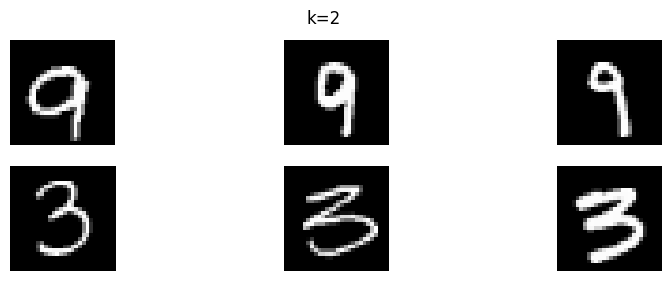

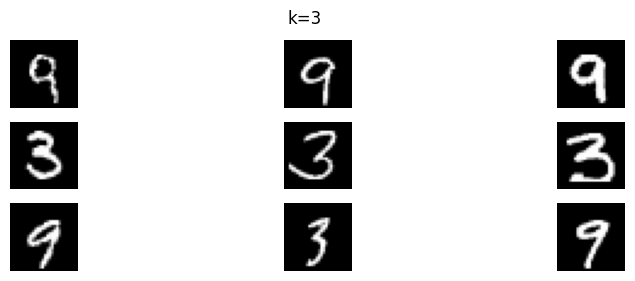

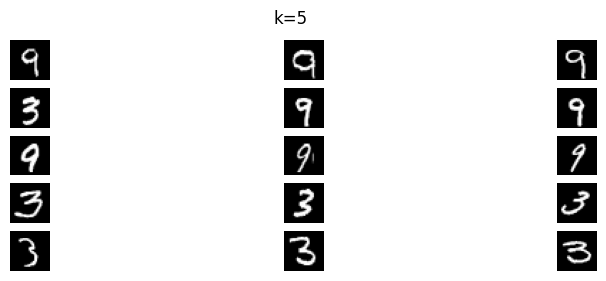

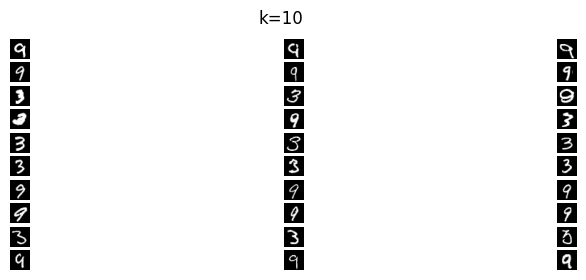

In [19]:
import matplotlib.pyplot as plt

def plot_cluster_samples(X, labels, k, samples_per_cluster=3):
    plt.figure(figsize=(10, 3))
    for cluster_id in range(k):
        cluster_indices = np.where(labels == cluster_id)[0]
        chosen = np.random.choice(cluster_indices, samples_per_cluster, replace=False)
        for i, idx in enumerate(chosen):
            plt.subplot(k, samples_per_cluster, cluster_id * samples_per_cluster + i + 1)
            plt.imshow(X[idx].reshape(28, 28), cmap='gray')
            plt.axis('off')
    plt.suptitle(f"k={k}")
    plt.show()

for k in [2, 3, 5, 10]:
    labels, _ = run_kmeans(X, k)
    plot_cluster_samples(X, labels, k)

In [23]:
dims = [2, 5, 10]
pca_data = {}

for d in dims:
    pca = PCA(n_components=d, random_state=42)
    reduced = pca.fit_transform(X)
    pca_data[d] = reduced

results = {}
for d in dims:
    for k in [2, 3, 5, 10]:
        labels, _ = run_kmeans(pca_data[d], k)
        results[(d, k)] = labels

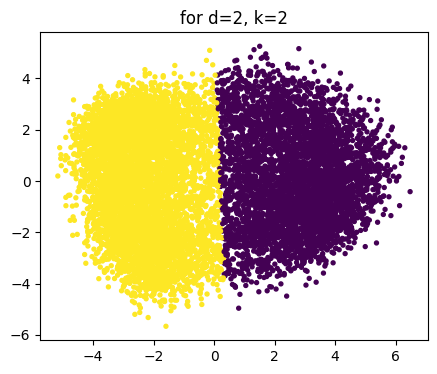

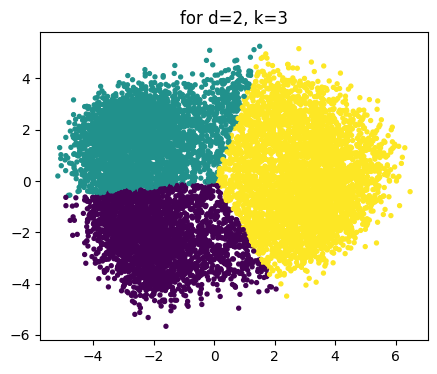

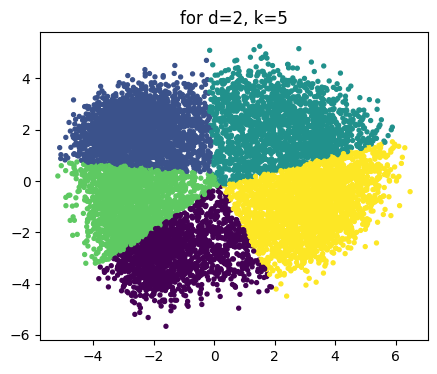

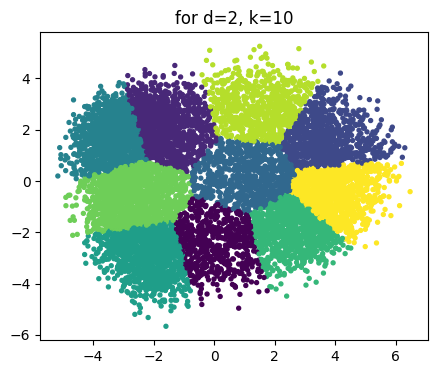

In [30]:
def plot_2d_clusters(X_2d, labels, k):
    plt.figure(figsize=(5, 4))
    plt.scatter(X_2d[:, 0], X_2d[:, 1], c=labels, s=8)
    plt.title(f"for d=2, k={k}")
    plt.show()

for k in [2, 3, 5, 10]:
    plot_2d_clusters(pca_data[2], results[(2, k)], k)

In [26]:
from sklearn.metrics import silhouette_score

for d in [5, 10]:
    for k in [2, 3, 5, 10]:
        labels = results[(d, k)]
        score = silhouette_score(pca_data[d], labels)
        print(f"Silhouette score for PCA {d}D, k={k}: {score:.3f}")

Silhouette score for PCA 5D, k=2: 0.299
Silhouette score for PCA 5D, k=3: 0.283
Silhouette score for PCA 5D, k=5: 0.258
Silhouette score for PCA 5D, k=10: 0.208
Silhouette score for PCA 10D, k=2: 0.228
Silhouette score for PCA 10D, k=3: 0.208
Silhouette score for PCA 10D, k=5: 0.180
Silhouette score for PCA 10D, k=10: 0.163


# Report



1. What is the goal of clustering? What is k-Means clustering? Explain why it is an unsupervised algorithm.

2. KMeans is an unsupervised algorithm, so we can use it even without label information in real applications. However, since we have the labels in this homework (‘3’s and ‘9’s), which method (raw vs. dim-reduced, different k values) produced the 'best' clusters according to the labels? Why?

3. If we had no prior knowledge of our data categories, how could we judge whether the clusters are meaningful? (Hint: do some research on internal validation metrics, visualization, interpretability).

4. How can we decide the “right” value of k in a k-Means algorithm? Search for general strategies, and explain one. Is there a universal rule-of-thumb strategy? Why yes or why not?

5. Does the way you initialize centroids affect the final clusters? Why? (You may try different initialization methods if you wish, e.g., choosing random data samples as centroids instead of random points in the space.)

6. How does reducing the dimensionality of a dataset affect clustering results in terms of interpretability, computation, and performance? When do you think it is beneficial to use such strategy?

7. Conclude with your main takeaways from this homework: what you learned, what worked well, and what challenges you encountered.

**My Answers**

1. The goal of clustering is to group similar data points together so that the data in the same group are more similar to each other than to data in other groups.
K-Means clustering is an algorithm that divides data into k groups by finding cluster centers (called centroids) and assigning each point to the nearest one.
It is unsupervised because it doesn’t use any label information — it just tries to find patterns by itself, based on distances between points.
2. In this homework, we actually know the true labels, so I compared the results with them. I found that when k=2 and using the 2D PCA reduced data, the clusters looked the most separated between 3 and 9. When I used higher dimensions or larger k, the clusters started mixing more. So I think the 2D PCA with k=2 made the “best” clusters because it captured the main difference between the two digits in a simple way.
3. If we don’t have labels, we can use something called internal validation metrics, like Silhouette score. These score tells how far clusters are from each other and how dense they are inside. Also, for 2D or 3D data we can use visualization to see if the clusters are really separated. Another way is to check if the clusters make sense in real life.
4. A common strategy is the elbow method. we plot the total within cluster distance for different k values and look for a point where the decrease slows down like an elbow shape. That point is often a good k. But there is no universal rule because it depends on the data shape and what we want to find.
Different datasets can need different k values.
5. Yes, it does. If we choose very different initial centroids, the algorithm might end up in different final clusters. This happens because K-Means can get stuck in local minima. That’s why many implementations use the k-means++ initialization, which spreads the first centroids apart and usually gives better results.
6. Reducing dimensionality (like PCA) can make clustering faster and easier to interpret because there are fewer features. It also removes noise and makes visualization possible in 2D or 3D. But sometimes it can lose important information too, so the clusters may become less accurate. It’s good to use when the original data has too many features or too much noise.
7. From this homework, I learned how K-Means actually works and how PCA helps to understand high-dimensional data. What worked well was the 2D PCA visualization. I could really see the 3 and 9 separated. It was fun to test different k values, but it was confusing at first to interpret the results because there is no correct answer. Overall, I understood better what unsupervised learning means and how clustering is used in real data.

** I used GenAI to unnatural parts of my English.